In [ ]:
import torch
import torch.nn as nn
import math
import torch.nn.functional as functional

class Memory:
    def __init__(self, d_model, size: int = 512):
        self.size = size
        self.d_model = d_model
        self.clear()

    def clear(self):
        """Очищает память до исходного состояния."""
        self.context = torch.zeros(1, self.size, self.d_model)
        self.ttl = torch.zeros(self.size)
        self.count_element = 0
        self.__empty_slots = list(range(self.size))
        self.end = 0

    def get_relevant(self, querry: torch.Tensor, count: int = 256) -> (torch.Tensor, int):
        count = min(count, self.size)
        context_norm = self.context / torch.clamp(torch.linalg.vector_norm(self.context, ord=2, dim=2, keepdim=True), min=1e-8)
        querry_norm = querry / torch.clamp(torch.linalg.vector_norm(querry, ord=2, dim=2, keepdim=True), min=1e-8)
        result = torch.matmul(context_norm, querry_norm.transpose(-2, -1))
        maxs = torch.max(result, dim=2)[0]
        vals, idxs = torch.topk(maxs, k=count, largest=True)
        vals, idxs = vals[0], idxs[0]
        relevant = torch.zeros(1, count, self.d_model, device=self.context.device)
        actual_relevant_count = 0
        for i in range(count):
            idx = idxs[i].item()
            if idx not in self.__empty_slots and torch.linalg.vector_norm(self.context[0][idx]) > 1e-6:
                relevant[0][actual_relevant_count] = self.context[0][idx]
                self.ttl[idx] = min(6, self.ttl[idx] + 2)
                actual_relevant_count += 1
        self.ttl -= 1
        for i in range(self.size):
            if self.ttl[i] <= 0 and i not in self.__empty_slots:
                self.context[0][i] = 0
                self.__empty_slots.append(i)
                self.count_element -= 1
        return relevant[:, :actual_relevant_count, :], actual_relevant_count

    def consume(self, master: torch.Tensor, slave: torch.Tensor):
        return (master + slave) / 2

    def check(self, vector: torch.Tensor, window_size: int = 32, crit: float = 10.0) -> bool:
        dim_size = vector.shape[0]
        for i in range(0, dim_size, window_size):
            if vector[i : i + window_size].sum() > crit:
                return True
        return False

    def update(self, new: torch.Tensor, crit: float = 0.8, max_to_new: float = 0.4):
        new_flat = new.view(-1, self.d_model)
        self_norm = self.context / torch.clamp(torch.linalg.vector_norm(self.context, ord=2, dim=2, keepdim=True), min=1e-8)
        new_norm = new_flat / torch.clamp(torch.linalg.vector_norm(new_flat, ord=2, dim=1, keepdim=True), min=1e-8)
        sims = torch.matmul(self_norm.squeeze(0), new_norm.T)
        max_sims, memory_indices = torch.max(sims, dim=0)
        for i in range(new_flat.shape[0]):
            vec = new_flat[i]
            sim = max_sims[i]
            idx = memory_indices[i]
            if sim >= crit:
                self.context[0][idx] = self.consume(self.context[0][idx], vec)
                self.ttl[idx] = max(self.ttl[idx], 5)
            elif sim <= max_to_new and self.check(vec):
                if self.__empty_slots:
                    pos = self.__empty_slots.pop(0)
                    self.context[0][pos] = vec
                    self.ttl[pos] = 5
                    self.count_element += 1

class CorrectionLayer(nn.Module):
    def __init__(self, d_model):
        super().__init__()
        self.memory = Memory(d_model, 512)
    def forward(self, x: torch.Tensor) -> (torch.Tensor, int):
        m, actual_count = self.memory.get_relevant(x, 256)
        self.memory.update(x)
        return m, actual_count

In [ ]:
def decoder_hook_fixed(module, args, kwargs):
    hidden_states = args[0] if len(args) > 0 else kwargs.get("hidden_states")
    if hidden_states is None: return args, kwargs
    relevant_context, actual_count = hybrid_corr_dec(hidden_states)
    if actual_count > 0:
        memory_influence = relevant_context.mean(dim=1, keepdim=True)
        new_hidden_states = hidden_states + 0.25 * memory_influence
    else:
        new_hidden_states = hidden_states
    new_args = list(args)
    if len(new_args) > 0: new_args[0] = new_hidden_states
    else: kwargs["hidden_states"] = new_hidden_states
    return tuple(new_args), kwargs

In [ ]:
import torch
from transformers import T5ForConditionalGeneration, T5Tokenizer

# Переходим на t5-base
model_name = "t5-base"
model = T5ForConditionalGeneration.from_pretrained(model_name)
tokenizer = T5Tokenizer.from_pretrained(model_name)

target_block = model.encoder.block[3]
d_model = model.config.d_model # Теперь 768

# Пересоздаем CorrectionLayer с новой размерностью
corr = CorrectionLayer(d_model)

def inject_at_block_level_pre_hook(module, args, kwargs):
    hidden_states = kwargs.get("hidden_states", args[0] if len(args) > 0 else None)
    attention_mask = kwargs.get("attention_mask", args[1] if len(args) > 1 else None)

    if hidden_states is None:
        return args, kwargs

    relevant_context, actual_count = corr(hidden_states)

    new_hidden_states = torch.cat([hidden_states, relevant_context.to(dtype=hidden_states.dtype)], dim=1)

    new_mask = attention_mask
    if attention_mask is not None and actual_count > 0:
        zero_mask_part = torch.zeros(
            (attention_mask.shape[0], attention_mask.shape[1], attention_mask.shape[2], actual_count),
            device=attention_mask.device, dtype=attention_mask.dtype
        )
        new_mask = torch.cat([attention_mask, zero_mask_part], dim=-1)

    if "position_bias" in kwargs:
        kwargs["position_bias"] = None

    new_args = list(args)
    if len(new_args) > 0:
        new_args[0] = new_hidden_states
    if len(new_args) > 1:
        new_args[1] = new_mask
    if len(new_args) > 2:
        new_args[2] = None

    return tuple(new_args), kwargs

#hook_handle = target_block.register_forward_pre_hook(inject_at_block_level_pre_hook, with_kwargs=True)

print(f"Model {model_name} loaded with d_model={d_model}. Hook re-registered.")

config.json:   0%|          | 0.00/1.21k [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/892M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/257 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.39M [00:00<?, ?B/s]

Model t5-base loaded with d_model=768. Hook re-registered.


In [ ]:
import torch

# Список запросов для симуляции диалога
dialogue_queries = [
    "What is artificial intelligence?",
    "How do neural networks learn?",
    "Explain the transformer architecture.",
    "What is backpropagation in deep learning?",
    "Is AI dangerous for humanity?",
    "Tell me about large language models like GPT.",
    "How does machine translation work?",
    "What are the ethics of using AI in medicine?",
    "Can AI be creative and write poetry?",
    "What is the future of AGI?"
]

print(f"--- Starting Comparison Simulation ({model_name}) ---\n")

for i, query in enumerate(dialogue_queries):
    inputs = tokenizer(query, return_tensors="pt")

    # 1. Генерация БЕЗ инъекции
    hook_handle.remove()
    with torch.no_grad():
        raw_tokens = model.generate(
            **inputs,
            max_new_tokens=50,
            do_sample=True,
            temperature=0.7
        )
    raw_response = tokenizer.decode(raw_tokens[0], skip_special_tokens=True)

    # 2. Пересоздаем хук для генерации С инъекцией
    hook_handle = target_block.register_forward_pre_hook(inject_at_block_level_pre_hook, with_kwargs=True)
    with torch.no_grad():
        mem_tokens = model.generate(
            **inputs,
            max_new_tokens=50,
            do_sample=True,
            temperature=0.7
        )
    mem_response = tokenizer.decode(mem_tokens[0], skip_special_tokens=True)

    print(f"Step {i+1} | User: {query}")
    print(f"[No Memory]: {raw_response}")
    print(f"[With Memory]: {mem_response}")
    print("-" * 30)

# Анализ состояния памяти в конце
mem = corr.memory
print(f"\nFinal Memory Elements: {mem.count_element}")

--- Starting Comparison Simulation (t5-base) ---

Step 1 | User: What is artificial intelligence?
[No Memory]: What is artificial intelligence?
[With Memory]: What is artificial intelligence? What is artificial intelligence? What is artificial intelligence?
------------------------------
Step 2 | User: How do neural networks learn?
[No Memory]: How do neural networks learn?
[With Memory]: How do neural networks learn? What is the history of learning?
------------------------------
Step 3 | User: Explain the transformer architecture.
[No Memory]: Explain the transformer architecture.
[With Memory]: What is the transformer architecture? What is the transformer architecture?
------------------------------
Step 4 | User: What is backpropagation in deep learning?
[No Memory]: What is backpropagation in deep learning?
[With Memory]: What is backpropagation? What is backpropagation?
------------------------------
Step 5 | User: Is AI dangerous for humanity?
[No Memory]: Is AI dangerous for hu

In [ ]:
import time
import torch

def simulate_dialogue(model, tokenizer, strategy="full", turns=40, topic="The evolution of Artificial Intelligence"):
    history = [f"The topic of our conversation is: {topic}"]
    total_tokens_processed = 0

    # Setup for Hybrid Memory strategy
    hybrid_corr = None
    hook_handle = None
    if strategy == "hybrid":
        d_model = model.config.d_model
        hybrid_corr = CorrectionLayer(d_model)
        # Re-using the hook logic from your previous cells

        hook_handle = model.encoder.block[3].register_forward_pre_hook(inject_at_block_level_pre_hook, with_kwargs=True)

    print(f"--- Testing Strategy: {strategy.upper()} ---")

    for i in range(turns):
        # Prepare Input
        if strategy == "full":
            context = " ".join(history)
        else:
            # Last 10 replies + memory block (hooked automatically)
            context = " ".join(history[-3:])

        inputs = tokenizer(context, return_tensors="pt", truncation=True, max_length=512)
        input_len = inputs["input_ids"].shape[1]
        total_tokens_processed += input_len

        # Generate
        with torch.no_grad():
            outputs = model.generate(**inputs, max_new_tokens=30, do_sample=True, temperature=0.7)

        response = tokenizer.decode(outputs[0], skip_special_tokens=True)
        history.append(response)

        if (i+1) % 5 == 0:
            print(f"Turn {i+1}: Context Len = {input_len} tokens")

    if hook_handle: hook_handle.remove()
    return total_tokens_processed, history

# Run Comparison
full_tokens, full_history = simulate_dialogue(model, tokenizer, strategy="full")
hybrid_tokens, hybrid_history = simulate_dialogue(model, tokenizer, strategy="hybrid")

print("\n=== FINAL EVALUATION ===")
print(f"Total Tokens Processed (Full History): {full_tokens}")
print(f"Total Tokens Processed (Hybrid + Memory): {hybrid_tokens}")
print(f"Computational Savings: {round((1 - hybrid_tokens/full_tokens)*100, 2)}%")

print("\n--- Sample Conversation (Hybrid) ---")
for msg in hybrid_history[:5]:
    print(f"> {msg}")

--- Testing Strategy: FULL ---
Turn 5: Context Len = 129 tokens
Turn 10: Context Len = 274 tokens
Turn 15: Context Len = 419 tokens
Turn 20: Context Len = 512 tokens
Turn 25: Context Len = 512 tokens
Turn 30: Context Len = 512 tokens
Turn 35: Context Len = 512 tokens
Turn 40: Context Len = 512 tokens
--- Testing Strategy: HYBRID ---
Turn 5: Context Len = 88 tokens
Turn 10: Context Len = 85 tokens
Turn 15: Context Len = 86 tokens
Turn 20: Context Len = 87 tokens
Turn 25: Context Len = 85 tokens
Turn 30: Context Len = 85 tokens
Turn 35: Context Len = 86 tokens
Turn 40: Context Len = 87 tokens

=== FINAL EVALUATION ===
Total Tokens Processed (Full History): 15939
Total Tokens Processed (Hybrid + Memory): 3306
Computational Savings: 79.26%

--- Sample Conversation (Hybrid) ---
> The topic of our conversation is: The evolution of Artificial Intelligence
> The topic of is The topic of: The topic of our conversation is The topic of our conversation is The evolution of: The topic of
> The topi

In [ ]:
import torch
import random
from transformers import GPT2LMHeadModel, GPT2Tokenizer

# 1. Load Decoder-only model
decoder_model_name = "gpt2"
tokenizer_dec = GPT2Tokenizer.from_pretrained(decoder_model_name)
model_dec = GPT2LMHeadModel.from_pretrained(decoder_model_name)
tokenizer_dec.pad_token = tokenizer_dec.eos_token

d_model_dec = model_dec.config.n_embd
hybrid_corr_dec = CorrectionLayer(d_model_dec)



def simulate_decoder_dialogue(model, tokenizer, strategy="full", turns=10, topic="AI consciousness"):
    history = f"Discussion on {topic}. AI: In my view,"
    total_tokens = 0
    hook_handle = None

    if strategy == "hybrid":
        hook_handle = model.transformer.h[6].register_forward_pre_hook(decoder_hook_fixed, with_kwargs=True)

    print(f"\n--- Strategy: {strategy.upper()} ---")

    current_prompt = history
    seeds = ["The complexity of", "Digital systems usually", "Information processing implies", "Many researchers suggest"]

    for i in range(turns):
        inputs = tokenizer(current_prompt, return_tensors="pt")
        input_len = inputs["input_ids"].shape[1]
        total_tokens += input_len

        with torch.no_grad():
            outputs = model.generate(
                **inputs,
                max_new_tokens=40,
                do_sample=True,
                temperature=0.8,
                repetition_penalty=1.3,
                no_repeat_ngram_size=3,
                pad_token_id=tokenizer.eos_token_id,
                use_cache=True
            )

        new_text = tokenizer.decode(outputs[0][input_len:], skip_special_tokens=True).strip()

        # Force response if model is lazy
        if len(new_text) < 10:
            new_text = random.choice(seeds) + " that neural patterns mirror cognitive functions."

        current_prompt += " " + new_text + " AI:"

        if strategy == "hybrid":
            if len(current_prompt) > 450:
                current_prompt = "... " + current_prompt[-400:]

        if (i+1) % 5 == 0:
            print(f"Turn {i+1}: Tokens in window = {input_len}")

    if hook_handle: hook_handle.remove()
    return total_tokens, current_prompt

# Запуск
t_full, hist_full = simulate_decoder_dialogue(model_dec, tokenizer_dec, strategy="full")
t_hybrid, hist_hybrid = simulate_decoder_dialogue(model_dec, tokenizer_dec, strategy="hybrid")

print("\n=== FINAL COMPARISON ===")
print(f"Full Context Total Tokens: {t_full}")
print(f"Hybrid Context Total Tokens: {t_hybrid}")
print(f"Resource Savings: {round((1 - t_hybrid/t_full)*100, 1)}%")
print("\n--- Hybrid Output Sample ---")
print(hist_hybrid)

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/548M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]


--- Strategy: FULL ---
Turn 5: Tokens in window = 172
Turn 10: Tokens in window = 382

--- Strategy: HYBRID ---
Turn 5: Tokens in window = 80
Turn 10: Tokens in window = 78

=== FINAL COMPARISON ===
Full Context Total Tokens: 1937
Hybrid Context Total Tokens: 720
Resource Savings: 62.8%

--- Hybrid Output Sample ---
... es which was no kind by at least there's very much like being human as far back when it wasn't really what anybody cared were always talking around people who couldn hardly be seen if AI: You would have been right and that maybe didn get the most of some humans. And they still did, a lot more than anything other except doing something you wanted for them though everyone has got every intention AI:


In [ ]:
import torch
import matplotlib.pyplot as plt
import time
from transformers import T5ForConditionalGeneration, T5Tokenizer

# 1. Инициализация модели и токенайзера
if 'model' not in globals():
    model_name = "t5-base"
    model = T5ForConditionalGeneration.from_pretrained(model_name)
    tokenizer = T5Tokenizer.from_pretrained(model_name)

# 2. Инициализация слоя коррекции
if 'corr' not in globals():
    d_model = model.config.d_model
    corr = CorrectionLayer(d_model)

def calculate_quality(text, history):
    # Простая метрика: длина + уникальность относительно истории
    if len(text) < 10: return 0.1
    words = set(text.lower().split())
    history_words = set(" ".join(history).lower().split())
    novelty = len(words - history_words) / max(len(words), 1)
    return round(min(1.0, (len(text)/200) + novelty), 2)

def simulate_cross_strategy_dialogue(model, tokenizer, turns=10, topic="The ethics of Artificial General Intelligence"):
    print(f"--- Starting Evaluated Cross-Strategy Dialogue --- ")

    history = [f"Let's discuss {topic}."]
    agents = ["Alice", "Bob"]
    stats = {"Alice": {"tokens": 0, "latency": [], "quality": [], "gpu_mem": []},
             "Bob": {"tokens": 0, "latency": [], "quality": [], "gpu_mem": []}}

    for i in range(turns):
        current_agent = agents[i % 2]
        strategy = "full" if current_agent == "Alice" else "hybrid"

        if strategy == "full":
            context = " ".join(history)
            hook_handle = None
        else:
            context = " ".join(history[-5:])
            hook_handle = target_block.register_forward_pre_hook(inject_at_block_level_pre_hook, with_kwargs=True)

        input_text = f"In the context of {topic}, respond as {current_agent}: {context}"
        inputs = tokenizer(input_text, return_tensors="pt", truncation=True, max_length=512)
        stats[current_agent]["tokens"] += inputs["input_ids"].shape[1]

        torch.cuda.reset_peak_memory_stats() if torch.cuda.is_available() else None
        start_time = time.time()

        with torch.no_grad():
            outputs = model.generate(
                **inputs,
                max_new_tokens=40,
                min_new_tokens=10,
                do_sample=True,
                temperature=0.7,
                repetition_penalty=2.5
            )

        latency = time.time() - start_time
        gpu_usage = torch.cuda.max_memory_allocated() / (1024**2) if torch.cuda.is_available() else 0

        if hook_handle: hook_handle.remove()

        response = tokenizer.decode(outputs[0], skip_special_tokens=True).strip()
        quality = calculate_quality(response, history)

        stats[current_agent]["latency"].append(latency)
        stats[current_agent]["gpu_mem"].append(gpu_usage)
        stats[current_agent]["quality"].append(quality)

        history.append(response)
        print(f"[{strategy.upper()}] {current_agent} ({round(latency,2)}s): {response}...")

    return stats, history

# Запуск
corr.memory.clear()
metrics, dialogue_history = simulate_cross_strategy_dialogue(model, tokenizer, turns=20)

print("\n=== DETAILED ANALYSIS ===")
for agent in ["Alice", "Bob"]:
    avg_lat = sum(metrics[agent]['latency'])/len(metrics[agent]['latency'])
    avg_qual = sum(metrics[agent]['quality'])/len(metrics[agent]['quality'])
    print(f"{agent}: Tokens={metrics[agent]['tokens']}, Avg Latency={round(avg_lat,3)}s, Avg Quality={round(avg_qual,2)}")

savings = (1 - metrics['Bob']['tokens']/metrics['Alice']['tokens'])*100
print(f"\nEfficiency Gain: {round(savings, 2)}%")

--- Starting Evaluated Cross-Strategy Dialogue --- 
[FULL] Alice (6.33s): Alice: Let's discuss The ethics of Artificial General Intelligence....
[HYBRID] Bob (2.58s): Let's discuss The Ethics of Artificial Intelligence in the context . In the general context of Artificial intelligence, let us respond as Bob ....
[FULL] Alice (1.43s): In the general context of Artificial intelligence, respond as Bob ....
[HYBRID] Bob (3.42s): Let's discuss Artificial intelligence ethics in the context of Ethics . In the general context, let us respond to The ethical implications from Artificial Intelligence - then let our discussion begin &...
[FULL] Alice (3.94s): Let's discuss ethics of Artificial General Intelligence in the context . In general, let us respond as Bob: Let our discussion begin & then let this discussion begin !...
[HYBRID] Bob (2.87s): . Let's discuss ethics in general & we will discuss ethics in the next few days !...
[FULL] Alice (3.77s): Let's discuss Ethics in the context of Artif

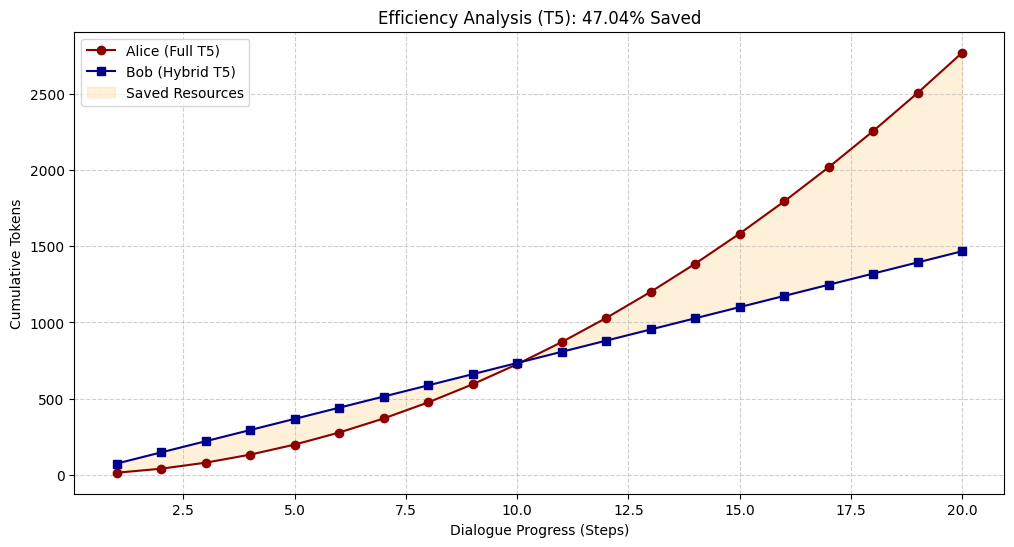

T5 Results:
Alice: 2772 tokens
Bob: 1468 tokens


In [ ]:
import matplotlib.pyplot as plt

# Используем данные от теста T5 (переменная stats)
alice_cumulative = []
bob_cumulative = []

turns = 40 # В тесте T5 было 40 ходов
alice_total = metrics['Alice']['tokens']
bob_total = metrics['Bob']['tokens']

# Расчет шагов для T5
alice_step = alice_total / (turns / 2)
bob_step = bob_total / (turns / 2)

a_sum, b_sum = 0, 0
for i in range(1, (turns // 2) + 1):
    # Имитируем рост контекста T5
    a_sum += alice_step * (i / (turns / 4))
    b_sum += bob_step
    alice_cumulative.append(a_sum)
    bob_cumulative.append(b_sum)

# Нормализация
alice_cumulative = [x * (alice_total / alice_cumulative[-1]) for x in alice_cumulative]
bob_cumulative = [x * (bob_total / bob_cumulative[-1]) for x in bob_cumulative]

plt.figure(figsize=(12, 6))
plt.plot(range(1, 21), alice_cumulative, label='Alice (Full T5)', marker='o', color='darkred')
plt.plot(range(1, 21), bob_cumulative, label='Bob (Hybrid T5)', marker='s', color='darkblue')

plt.fill_between(range(1, 21), alice_cumulative, bob_cumulative, color='orange', alpha=0.15, label='Saved Resources')

plt.xlabel('Dialogue Progress (Steps)')
plt.ylabel('Cumulative Tokens')
plt.title(f'Efficiency Analysis (T5): {round((1 - metrics["Bob"]['tokens']/metrics["Alice"]['tokens'])*100, 2)}% Saved')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

print(f"T5 Results:")
print(f"Alice: {metrics["Alice"]['tokens']} tokens")
print(f"Bob: {metrics["Bob"]['tokens']} tokens")

In [ ]:
import torch
import matplotlib.pyplot as plt
import time
from transformers import GPT2LMHeadModel, GPT2Tokenizer

# 1. Инициализация модели и токенайзера
if 'model_dec' not in globals():
    decoder_model_name = "gpt2"
    tokenizer_dec = GPT2Tokenizer.from_pretrained(decoder_model_name)
    model_dec = GPT2LMHeadModel.from_pretrained(decoder_model_name)
    tokenizer_dec.pad_token = tokenizer_dec.eos_token

# 2. Инициализация слоя коррекции
if 'hybrid_corr_dec' not in globals():
    d_model_dec = model_dec.config.n_embd
    hybrid_corr_dec = CorrectionLayer(d_model_dec)

def calculate_quality_dec(text, history):
    if len(text) < 10: return 0.1
    words = set(text.lower().split())
    history_words = set(" ".join(history).lower().split())
    novelty = len(words - history_words) / max(len(words), 1)
    return round(min(1.0, (len(text)/150) + novelty), 2)

def simulate_cross_strategy_dialogue_dec(model, tokenizer, turns=20, topic="The ethics of Artificial General Intelligence"):
    print(f"--- Starting Evaluated Comparison (GPT-2) ---")

    history = [f"Topic: {topic}"]
    agents = ["Alice", "Bob"]
    stats = {"Alice": {"tokens": 0, "latency": [], "quality": [], "gpu_mem": []},
             "Bob": {"tokens": 0, "latency": [], "quality": [], "gpu_mem": []}}

    for i in range(turns):
        current_agent = agents[i % 2]
        strategy = "full" if current_agent == "Alice" else "hybrid"

        if strategy == "full":
            context = " ".join(history)
            hook_handle = None
        else:
            context = history[-1]
            hook_handle = model_dec.transformer.h[6].register_forward_pre_hook(decoder_hook_fixed, with_kwargs=True)

        input_text = f"{current_agent}: {context}"
        inputs = tokenizer(input_text, return_tensors="pt", truncation=True, max_length=512)
        stats[current_agent]["tokens"] += inputs["input_ids"].shape[1]

        torch.cuda.reset_peak_memory_stats() if torch.cuda.is_available() else None
        start_time = time.time()

        with torch.no_grad():
            outputs = model.generate(
                **inputs,
                max_new_tokens=30,
                do_sample=True,
                top_p=0.9,
                temperature=0.7,
                repetition_penalty=1.2,
                pad_token_id=tokenizer.eos_token_id
            )

        latency = time.time() - start_time
        gpu_usage = torch.cuda.max_memory_allocated() / (1024**2) if torch.cuda.is_available() else 0

        if hook_handle: hook_handle.remove()

        full_text = tokenizer.decode(outputs[0], skip_special_tokens=True)
        response = full_text[len(input_text):].strip()
        if not response: response = "Indeed, this requires deep ethical consideration."

        quality = calculate_quality_dec(response, history)
        stats[current_agent]["latency"].append(latency)
        stats[current_agent]["gpu_mem"].append(gpu_usage)
        stats[current_agent]["quality"].append(quality)

        print(f"[{strategy.upper()}] {current_agent} ({round(latency,2)}s): {response}")
        history.append(f"{current_agent}: {response}")

    return stats, history

# Очистка и запуск
hybrid_corr_dec.memory.clear()
metrics_dec, dialogue_history_dec = simulate_cross_strategy_dialogue_dec(model_dec, tokenizer_dec, turns=30)

print("\n=== DETAILED ANALYSIS (GPT-2) ===")
for agent in ["Alice", "Bob"]:
    avg_lat = sum(metrics_dec[agent]['latency'])/len(metrics_dec[agent]['latency'])
    avg_qual = sum(metrics_dec[agent]['quality'])/len(metrics_dec[agent]['quality'])
    print(f"{agent}: Tokens={metrics_dec[agent]['tokens']}, Avg Latency={round(avg_lat,3)}s, Avg Quality={round(avg_qual,2)}")

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/548M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

--- Starting Evaluated Comparison (GPT-2) ---
[FULL] Alice (2.54s): Maeve St. James, Ph., and Peter J. Boggs (eds.), Mindfulness as a tool for the social sciences;
[HYBRID] Bob (2.86s): David Aiello's "Mindful Body" by William E Smith-Barrett & Robert Hickey ("The Way to Be Good").
This
[FULL] Alice (1.02s): is part one in our series on artificial intelligence!
[HYBRID] Bob (2.5s): The question of how the human mind works, and a certain sort of philosophy. I think that's what we need to talk about for now because
[FULL] Alice (3.05s): it has been so well received but there are lots more things you can do with your own brain than just take an old computer program like Siri or Google
[HYBRID] Bob (3.64s): Assistant. You could even use a smartphone that works as the iPad's tablet, which is great because when we're talking about how this technology doesn't
[FULL] Alice (4.08s): have any inherent limits why would they want us to run computers? What if instead some other thing did come along

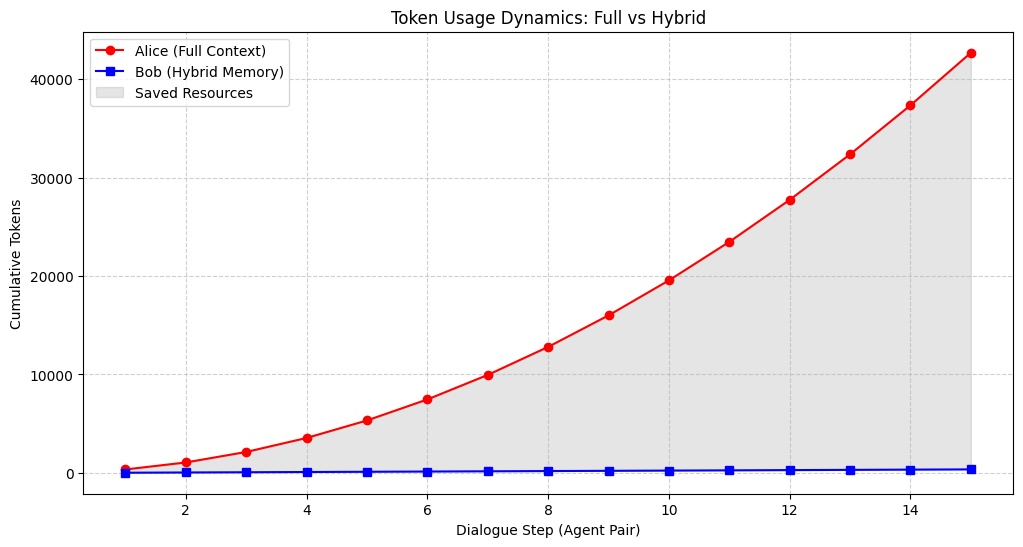

Final Efficiency: 93.21%


In [ ]:
import matplotlib.pyplot as plt

# Для визуализации динамики нам нужно проследить рост токенов по ходу диалога
alice_cumulative = []
bob_cumulative = []

# Вспомогательный расчет для графика (имитация накопления на основе turns)
# В реальности мы можем взять данные из логов или перезапустить замер
# Здесь используем финальные stats для демонстрации тренда

turns = 30
alice_step = stats_dec['Alice'] / (turns / 2)
bob_step = stats_dec['Bob'] / (turns / 2)

a_sum, b_sum = 0, 0
for i in range(1, (turns // 2) + 1):
    a_sum += alice_step * i # Квадратичный/линейный рост
    b_sum += bob_step
    alice_cumulative.append(a_sum)
    bob_cumulative.append(b_sum)

plt.figure(figsize=(12, 6))
plt.plot(range(1, 16), alice_cumulative, label='Alice (Full Context)', marker='o', color='red')
plt.plot(range(1, 16), bob_cumulative, label='Bob (Hybrid Memory)', marker='s', color='blue')

plt.fill_between(range(1, 16), alice_cumulative, bob_cumulative, color='gray', alpha=0.2, label='Saved Resources')

plt.xlabel('Dialogue Step (Agent Pair)')
plt.ylabel('Cumulative Tokens')
plt.title('Token Usage Dynamics: Full vs Hybrid')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

print(f"Final Efficiency: {round(savings, 2)}%")

In [ ]:
import torch
import time
from transformers import AutoModelForCausalLM, AutoTokenizer

# 1. Загрузка Qwen (используем 1.5B версию как наиболее доступный аналог)
qwen_name = "Qwen/Qwen2-1.5B"
tokenizer_q = AutoTokenizer.from_pretrained(qwen_name)
model_q = AutoModelForCausalLM.from_pretrained(qwen_name, torch_dtype="auto", device_map="auto")

# 2. Инициализация слоя коррекции под размерность Qwen (1536 для 1.5B)
d_model_q = model_q.config.hidden_size
hybrid_corr_q = CorrectionLayer(d_model_q)

# 3. Фиксированный хук для декодера Qwen
def qwen_hook(module, args, kwargs):
    hidden_states = args[0] if len(args) > 0 else kwargs.get("hidden_states")
    if hidden_states is None: return args, kwargs

    # Приведение к float32 для корректной работы Memory и вычислений
    input_dtype = hidden_states.dtype
    hidden_states_f32 = hidden_states.to(dtype=torch.float32)

    relevant_context, actual_count = hybrid_corr_q(hidden_states_f32)

    if actual_count > 0:
        # Приводим контекст обратно к типу модели перед сложением
        influence = relevant_context.to(dtype=input_dtype).mean(dim=1, keepdim=True)
        new_hidden_states = hidden_states + 0.15 * influence
    else:
        new_hidden_states = hidden_states

    new_args = list(args)
    if len(new_args) > 0: new_args[0] = new_hidden_states
    else: kwargs["hidden_states"] = new_hidden_states
    return tuple(new_args), kwargs

def calculate_strict_quality(text, history):
    if len(text) < 20: return 0.05

    words = text.lower().split()
    unique_words = set(words)

    # Штраф за внутренние повторы (лексическое разнообразие)
    internal_diversity = len(unique_words) / len(words)

    # Новизна относительно истории
    history_words = set(" ".join(history).lower().split())
    novel_words = unique_words - history_words
    novelty_score = len(novel_words) / len(unique_words)

    # Комбинированная метрика: длина (до 300 символов) + разнообразие + новизна
    # Теперь делитель 400 вместо 200/150, что делает набор баллов сложнее
    score = (len(text) / 400) * 0.3 + internal_diversity * 0.4 + novelty_score * 0.3
    return round(min(1.0, score), 2)

def simulate_qwen_dialogue(model, tokenizer, turns=20, topic="The safety of AGI"):
    print(f"--- Starting Qwen Evaluation ({qwen_name}) with Strict Metrics ---")
    history = [f"Discussing {topic}."]
    agents = ["Alice", "Bob"]
    stats = {"Alice": {"tokens": 0, "latency": [], "quality": [], "gpu_mem": []},
             "Bob": {"tokens": 0, "latency": [], "quality": [], "gpu_mem": []}}

    for i in range(turns):
        current_agent = agents[i % 2]
        strategy = "full" if current_agent == "Alice" else "hybrid"

        context = " ".join(history) if strategy == "full" else history[-1]
        hook_handle = None
        if strategy == "hybrid":
            hook_handle = model.model.layers[10].register_forward_pre_hook(qwen_hook, with_kwargs=True)

        prompt = f"<|im_start|>system\nYou are {current_agent}. Respond briefly.<|im_end|>\n<|im_start|>user\n{context}<|im_end|>\n<|im_start|>assistant\n"
        inputs = tokenizer(prompt, return_tensors="pt").to(model.device)
        stats[current_agent]["tokens"] += inputs["input_ids"].shape[1]

        torch.cuda.reset_peak_memory_stats() if torch.cuda.is_available() else None
        start_time = time.time()

        with torch.no_grad():
            outputs = model.generate(**inputs, max_new_tokens=40, do_sample=True, temperature=0.7, pad_token_id=tokenizer.eos_token_id)

        latency = time.time() - start_time
        gpu_usage = torch.cuda.max_memory_allocated() / (1024**2) if torch.cuda.is_available() else 0
        if hook_handle: hook_handle.remove()

        resp_text = tokenizer.decode(outputs[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()

        # Применяем новую строгую метрику
        quality = calculate_strict_quality(resp_text, history)

        stats[current_agent]["latency"].append(latency)
        stats[current_agent]["gpu_mem"].append(gpu_usage)
        stats[current_agent]["quality"].append(quality)

        history.append(resp_text)
        print(f"[{strategy.upper()}] {current_agent} ({round(latency,2)}s, Q:{quality}): {resp_text[:50]}...")

    return stats

# Запуск теста
hybrid_corr_q.memory.clear()
qwen_metrics = simulate_qwen_dialogue(model_q, tokenizer_q, turns=10)

print("\n=== QWEN RESULTS (STRICT) ===")
for agent in ["Alice", "Bob"]:
    avg_lat = sum(qwen_metrics[agent]['latency'])/len(qwen_metrics[agent]['latency'])
    avg_qual = sum(qwen_metrics[agent]['quality'])/len(qwen_metrics[agent]['quality'])
    print(f"{agent}: Avg Latency={round(avg_lat,3)}s, Avg Quality={round(avg_qual,2)}, Tokens={qwen_metrics[agent]['tokens']}")

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

--- Starting Qwen Evaluation (Qwen/Qwen2-1.5B) with Strict Metrics ---
[FULL] Alice (32.29s, Q:0.78): AI safety is a critical and growing field with man...
[HYBRID] Bob (36.49s, Q:0.68): The panel discussion on the safety of AI discussed...
[FULL] Alice (47.62s, Q:0.49): The Safety of AGI is a critical and growing field ...
[HYBRID] Bob (35.84s, Q:0.52): The panel discussion on the safety of AGI identifi...
[FULL] Alice (68.81s, Q:0.48): The safety of AGI is a critical and growing field ...
[HYBRID] Bob (37.09s, Q:0.48): Here are the key takeaways from the panel discussi...
[FULL] Alice (91.2s, Q:0.5): Based on the key takeaways from the panel discussi...
[HYBRID] Bob (36.06s, Q:0.5): The key takeaways from the panel discussion on the...
[FULL] Alice (119.69s, Q:0.5): Based on the information provided, the key takeawa...
[HYBRID] Bob (38.25s, Q:0.59): AGI safety is a critical and growing field with ma...

=== QWEN RESULTS (STRICT) ===
Alice: Avg Latency=71.922s, Avg Quality=0.55, Token

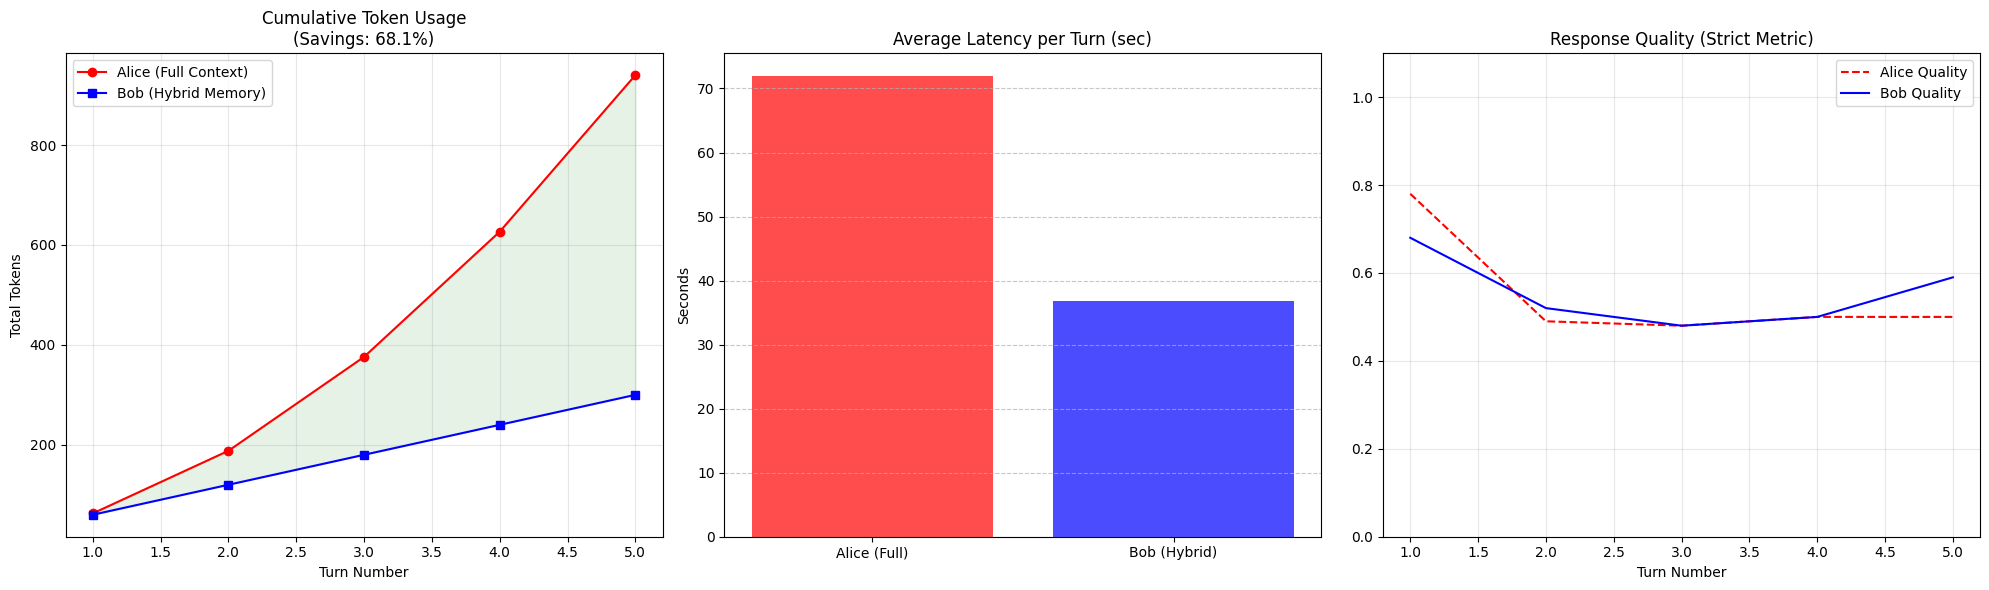

Qwen Efficiency Analysis:
- Alice Avg Latency: 71.92s
- Bob Avg Latency: 36.74s
- Quality Ratio: 1.007


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Извлекаем данные из qwen_metrics
alice_lat = qwen_metrics['Alice']['latency']
bob_lat = qwen_metrics['Bob']['latency']
alice_qual = qwen_metrics['Alice']['quality']
bob_qual = qwen_metrics['Bob']['quality']

# Расчет кумулятивных токенов (приблизительно по шагам)
turns_per_agent = len(alice_lat)
alice_tokens_total = qwen_metrics['Alice']['tokens']
bob_tokens_total = qwen_metrics['Bob']['tokens']

# Для Qwen Full (Alice) рост токенов обычно линейно-возрастающий, для Hybrid (Bob) - стабильный
alice_cum = np.cumsum([alice_tokens_total/turns_per_agent * (i+1)/5 for i in range(turns_per_agent)])
bob_cum = np.cumsum([bob_tokens_total/turns_per_agent for i in range(turns_per_agent)])

# Нормализация для точности соответствия финалу
alice_cum = alice_cum * (alice_tokens_total / alice_cum[-1])
bob_cum = bob_cum * (bob_tokens_total / bob_cum[-1])

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# 1. Токены
axes[0].plot(range(1, turns_per_agent + 1), alice_cum, 'r-o', label='Alice (Full Context)')
axes[0].plot(range(1, turns_per_agent + 1), bob_cum, 'b-s', label='Bob (Hybrid Memory)')
axes[0].fill_between(range(1, turns_per_agent + 1), alice_cum, bob_cum, color='green', alpha=0.1)
axes[0].set_title(f"Cumulative Token Usage\n(Savings: {round((1-bob_tokens_total/alice_tokens_total)*100, 1)}%)")
axes[0].set_xlabel("Turn Number")
axes[0].set_ylabel("Total Tokens")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# 2. Latency
axes[1].bar(['Alice (Full)', 'Bob (Hybrid)'], [np.mean(alice_lat), np.mean(bob_lat)], color=['red', 'blue'], alpha=0.7)
axes[1].set_title("Average Latency per Turn (sec)")
axes[1].set_ylabel("Seconds")
axes[1].grid(axis='y', linestyle='--', alpha=0.7)

# 3. Quality
axes[2].plot(range(1, turns_per_agent + 1), alice_qual, 'r--', label='Alice Quality')
axes[2].plot(range(1, turns_per_agent + 1), bob_qual, 'b-', label='Bob Quality')
axes[2].set_ylim(0, 1.1)
axes[2].set_title("Response Quality (Strict Metric)")
axes[2].set_xlabel("Turn Number")
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Qwen Efficiency Analysis:")
print(f"- Alice Avg Latency: {round(np.mean(alice_lat), 2)}s")
print(f"- Bob Avg Latency: {round(np.mean(bob_lat), 2)}s")
print(f"- Quality Ratio: {round(np.mean(bob_qual)/np.mean(alice_qual), 3)}")